10번째 코드
EfficientNet 기반 Arcface 판별로직으로 변경
확률값 추론 --> embedding 벡터 추출로 방식 변경

1차 결과
📊 Train Acc: 87.09% | Val Loss: 1.1419, Val Acc: 86.98%🛑 조기 종료

2차 결과(arcface margin 0.5 --> 0.7)
📊 Train Acc: 85.18% | Val Loss: 1.4744, Val Acc: 87.46%
🛑 조기 종료

3차 결과(추가적인 Augmentation)
🎯 [최종 결과] TTA 적용 Val Acc: 88.04% (기존 87.46%)

튜닝
IMG_SIZE: 224 --> 260 (anger, panic 구분 픽셀 확보)
ArcMarginProduct: m=0.5 -> 0.7(arcface 구분 마진 threshold 높이기)

In [2]:
import os
os.environ['OPENCV_LOG_LEVEL'] = 'ERROR' # OpenCV 경고 차단

import json
import cv2
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import timm
import albumentations as A
from albumentations.pytorch import ToTensorV2
from tqdm import tqdm
import random
import math

# ================= 설정 =================
RAW_IMG_BASE = "/workspace/user1/dataset_v2/img/train" 
LBL_BASE = "/workspace/user1/dataset_v2/label_mod/train"
VAL_IMG_BASE = "/workspace/user1/dataset_v2/img/val"
VAL_LBL_BASE = "/workspace/user1/dataset_v2/label_mod/val"
AUG_IMG_BASE = "/workspace/user5/img_augmented/train"

SAVE_DIR = '/workspace/user1/model_v8_arcface'
os.makedirs(SAVE_DIR, exist_ok=True)

SEED = 42
BATCH_SIZE = 64
# IMG_SIZE = 224
IMG_SIZE = 260
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Stage 2: 4가지 감정 매핑
STAGE2_MAP = {'anger': 0, 'happy': 1, 'panic': 2, 'sadness': 3}

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

seed_everything(SEED)
print(f"✅ 환경 설정 완료. 장치: {DEVICE}")

✅ 환경 설정 완료. 장치: cuda


In [3]:
class ArcFaceStage2Dataset(Dataset):
    def __init__(self, raw_img_base, aug_img_base, lbl_base, transform=None, is_train=True):
        self.transform = transform
        self.samples = []
        
        counts = {0: 0, 1: 0, 2: 0, 3: 0}

        # 1. 원본 데이터 로드 (Neutral 제외)
        if os.path.exists(lbl_base):
            for json_file in tqdm(os.listdir(lbl_base), desc="Loading JSONs"):
                if not json_file.endswith('.json'): continue
                with open(os.path.join(lbl_base, json_file), 'r', encoding='utf-8') as f:
                    data = json.load(f)
                    for item in data['images']:
                        if item.get('is_box_issue') == 'Yes': continue
                        emotion = item['final_emotion']
                        if emotion in ['neutral', 'blank']: continue
                        
                        label = STAGE2_MAP[emotion]
                        counts[label] += 1
                        self.samples.append({
                            'source': 'raw',
                            'img_path': os.path.join(raw_img_base, emotion, item['filename']),
                            'bbox': item['bbox'],
                            'label': label
                        })

        # 2. 증강 데이터 로드 (Train 시에만)
        if is_train and os.path.exists(aug_img_base):
            for emotion_name in STAGE2_MAP.keys():
                src_folder = os.path.join(aug_img_base, emotion_name)
                if not os.path.isdir(src_folder): continue
                
                label = STAGE2_MAP[emotion_name]
                for filename in os.listdir(src_folder):
                    counts[label] += 1
                    self.samples.append({
                        'source': 'aug',
                        'img_path': os.path.join(src_folder, filename),
                        'label': label
                    })

        print(f"✅ 로딩 완료. {counts}")

    def __len__(self): return len(self.samples)

    def __getitem__(self, idx):
        item = self.samples[idx]
        image = cv2.imread(item['img_path'])
        if image is None: return self.__getitem__(random.randint(0, len(self)-1))
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        
        if item['source'] == 'raw':
            box = item['bbox']
            x1, y1, x2, y2 = max(0, box['minX']), max(0, box['minY']), box['maxX'], box['maxY']
            image = image[y1:y2, x1:x2]
            
        if self.transform:
            image = self.transform(image=image)['image']
            
        return image, torch.tensor(item['label'], dtype=torch.long)

print("✅ 데이터셋 클래스 정의 완료.")

✅ 데이터셋 클래스 정의 완료.


In [4]:
train_transform = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.HorizontalFlip(p=0.5),
    A.ShiftScaleRotate(shift_limit=0.1, scale_limit=0.1, rotate_limit=15, p=0.5),
    A.ColorJitter(brightness=0.2, contrast=0.2, p=0.3),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2()
])

val_transform = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ToTensorV2()
])

train_dataset = ArcFaceStage2Dataset(RAW_IMG_BASE, AUG_IMG_BASE, LBL_BASE, transform=train_transform, is_train=True)
val_dataset = ArcFaceStage2Dataset(VAL_IMG_BASE, AUG_IMG_BASE, VAL_LBL_BASE, transform=val_transform, is_train=False)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=4, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=4, pin_memory=True)

print(f"✅ 로더 완료. Train: {len(train_dataset)} / Val: {len(val_dataset)}")

/home/user1/.conda/envs/mwkim/lib/python3.10/site-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)
Loading JSONs: 100%|██████████| 5/5 [00:00<00:00, 23.12it/s]

✅ 로딩 완료. {0: 4627, 1: 7189, 2: 7706, 3: 8003}


Loading JSONs: 100%|██████████| 5/5 [00:00<00:00, 71.60it/s]

✅ 로딩 완료. {0: 184, 1: 281, 2: 303, 3: 269}
✅ 로더 완료. Train: 27525 / Val: 1037


In [5]:
class ArcMarginProduct(nn.Module):
    def __init__(self, in_features, out_features, s=30.0, m=0.50):
        super(ArcMarginProduct, self).__init__()
        self.in_features, self.out_features = in_features, out_features
        self.s, self.m = s, m
        self.weight = nn.Parameter(torch.FloatTensor(out_features, in_features))
        nn.init.xavier_uniform_(self.weight)
        self.cos_m, self.sin_m = math.cos(m), math.sin(m)
        self.th, self.mm = math.cos(math.pi - m), math.sin(math.pi - m) * m

    def forward(self, input, label):
        cosine = F.linear(F.normalize(input), F.normalize(self.weight))
        sine = torch.sqrt(1.0 - torch.pow(cosine, 2))
        phi = cosine * self.cos_m - sine * self.sin_m
        phi = torch.where(cosine > self.th, phi, cosine - self.mm)
        one_hot = torch.zeros(cosine.size(), device=input.device)
        one_hot.scatter_(1, label.view(-1, 1).long(), 1)
        output = (one_hot * phi) + ((1.0 - one_hot) * cosine)
        return output * self.s

class ArcFaceEfficientNet(nn.Module):
    def __init__(self, num_classes=4):
        super(ArcFaceEfficientNet, self).__init__()
        self.backbone = timm.create_model('efficientnet_b2', pretrained=False, num_classes=0) 
        
        fer_url = "https://github.com/sb-ai-lab/EmotiEffLib/raw/main/models/affectnet_emotions/enet_b2_8.pt"
        try:
            loaded = torch.hub.load_state_dict_from_url(fer_url, map_location='cpu', weights_only=False)
            if hasattr(loaded, 'state_dict'): loaded = loaded.state_dict()
            filtered_dict = {k: v for k, v in loaded.items() if 'classifier' not in k and 'head' not in k}
            self.backbone.load_state_dict(filtered_dict, strict=False)
            print("✅ FER 가중치 주입 성공.")
        except: print("⚠️ FER 주입 실패. 기본 가중치 사용.")

        # self.arcface = ArcMarginProduct(in_features=1408, out_features=num_classes)
        self.arcface = ArcMarginProduct(in_features=1408, out_features=num_classes, s=30.0, m=0.7)

    def forward(self, images, labels=None):
        features = self.backbone(images)
        if labels is not None: return self.arcface(features, labels)
        return F.linear(F.normalize(features), F.normalize(self.arcface.weight)) * self.arcface.s

model = ArcFaceEfficientNet(num_classes=4).to(DEVICE)
print("✅ ArcFace 모델 구성 완료.")

✅ FER 가중치 주입 성공.
✅ ArcFace 모델 구성 완료.


In [6]:
# Anger 보정을 위해 약간의 가중치 유지
class_weights = torch.tensor([1.5, 1.0, 1.0, 1.0]).to(DEVICE)
criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.AdamW(model.parameters(), lr=5e-5, weight_decay=1e-2)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.1, patience=3)

NUM_EPOCHS = 40
PATIENCE = 7
best_val_loss = float('inf')
trigger_times = 0
SAVE_PATH = os.path.join(SAVE_DIR, 'best_stage2_arcface.pth')
scaler = torch.amp.GradScaler('cuda')

print("🚀 ArcFace 기반 Stage 2 학습 시작...")

for epoch in range(NUM_EPOCHS):
    model.train()
    running_loss, correct_train, total_train = 0.0, 0, 0
    pbar = tqdm(train_loader, desc=f"Ep [{epoch+1}/{NUM_EPOCHS}]")
    
    for images, labels in pbar:
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        optimizer.zero_grad()
        with torch.autocast(device_type='cuda', dtype=torch.float16):
            outputs = model(images, labels) # 학습 시 라벨 전달
            loss = criterion(outputs, labels)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        
        running_loss += loss.item() * images.size(0)
        _, pred = torch.max(outputs, 1)
        total_train += labels.size(0)
        correct_train += (pred == labels).sum().item()

    # Validation
    model.eval()
    val_loss, correct_val, total_val = 0.0, 0, 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            with torch.autocast(device_type='cuda', dtype=torch.float16):
                outputs = model(images) # 추론 시 라벨 없음
                loss = criterion(outputs, labels)
            val_loss += loss.item() * images.size(0)
            _, pred = torch.max(outputs, 1)
            total_val += labels.size(0)
            correct_val += (pred == labels).sum().item()

    v_loss = val_loss / len(val_dataset)
    v_acc = correct_val / total_val * 100
    scheduler.step(v_loss)
    
    print(f"📊 Train Acc: {correct_train/total_train*100:.2f}% | Val Loss: {v_loss:.4f}, Val Acc: {v_acc:.2f}%")

    if v_loss < best_val_loss:
        best_val_loss = v_loss
        torch.save(model.state_dict(), SAVE_PATH)
        print(f"  💾 모델 저장됨")
        trigger_times = 0
    else:
        trigger_times += 1
        if trigger_times >= PATIENCE:
            print("🛑 조기 종료"); break

🚀 ArcFace 기반 Stage 2 학습 시작...


Ep [1/40]:   0%|          | 0/431 [00:00<?, ?it/s]

Invalid SOS parameters for sequential JPEG
Ep [1/40]:   4%|▍         | 18/431 [00:38<10:30,  1.53s/it]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [1/40]:  11%|█         | 46/431 [01:16<05:21,  1.20it/s]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [1/40]:  20%|█▉        | 85/431 [02:10<06:50,  1.19s/it]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [1/40]:  21%|██        | 90/431 [02:15<04:22,  1.30it/s]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [1/40]:  23%|██▎       | 98/431 [02:26<04:49,  1.15it/s]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [1/40]:  25%|██▍       | 106/431 [02:37<04:30,  1.20it/s]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG


📊 Train Acc: 25.38% | Val Loss: 1.6172, Val Acc: 84.57%
  💾 모델 저장됨


Ep [2/40]:   4%|▎         | 16/431 [00:24<07:01,  1.01s/it]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [2/40]:   5%|▍         | 20/431 [00:30<06:02,  1.13it/s]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [2/40]:  14%|█▍        | 60/431 [01:24<05:13,  1.18it/s]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [2/40]:  17%|█▋        | 72/431 [01:40<04:44,  1.26it/s]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [2/40]:  18%|█▊        | 76/431 [01:45<04:55,  1.20it/s]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [2/40]:  29%|██▉       | 124/431 [02:47<04:18,  1.19it/s]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [2/40]:  32%|███▏      | 136/431 [03:02<03:42,  1.33it/s]Invalid SOS parameters for

📊 Train Acc: 60.23% | Val Loss: 1.7735, Val Acc: 85.05%


... (18 outputs left out)

Ep [12/40]:   0%|          | 0/431 [00:00<?, ?it/s]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [12/40]:   2%|▏         | 8/431 [00:10<04:53,  1.44it/s]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [12/40]:   5%|▍         | 20/431 [00:24<04:34,  1.50it/s]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [12/40]:   9%|▉         | 40/431 [00:45<04:47,  1.36it/s]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [12/40]:  10%|█         | 44/431 [00:50<04:39,  1.38it/s]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [12/40]:  15%|█▍        | 64/431 [01:12<04:39,  1.31it/s]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [12/40]:  18%|█▊        | 76/431 [01:26<04:17,  1.38it/s]Invalid SOS parameters for sequ

📊 Train Acc: 84.59% | Val Loss: 1.4966, Val Acc: 87.56%


Ep [13/40]:   0%|          | 0/431 [00:00<?, ?it/s]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [13/40]:   3%|▎         | 12/431 [00:19<05:05,  1.37it/s] Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [13/40]:  15%|█▌        | 66/431 [01:35<09:31,  1.56s/it]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [13/40]:  17%|█▋        | 73/431 [01:42<06:15,  1.05s/it]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [13/40]:  24%|██▎       | 102/431 [02:16<04:17,  1.28it/s]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [13/40]:  26%|██▌       | 110/431 [02:25<03:39,  1.46it/s]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Ep [13/40]:  29%|██▉       | 126/431 [02:45<

📊 Train Acc: 85.18% | Val Loss: 1.4744, Val Acc: 87.46%
🛑 조기 종료


Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS

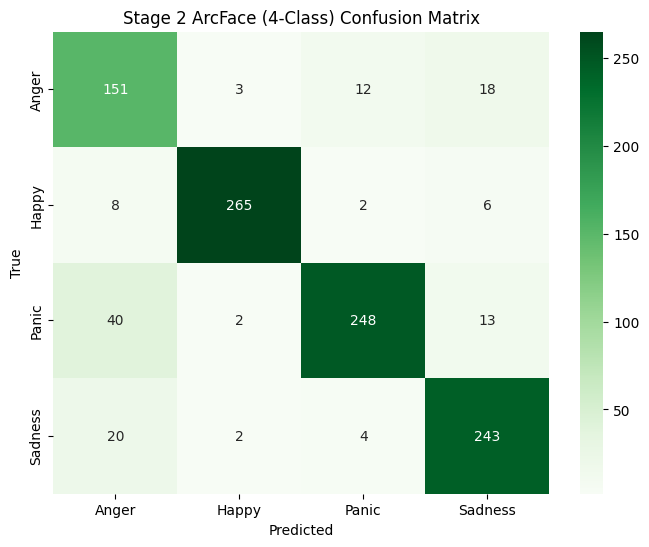

In [7]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# 현재 학습된 ArcFace 모델 로드 (동일 노트북이면 model 변수 그대로 사용 가능)
model.eval()

all_preds, all_labels = [], []
with torch.no_grad():
    for imgs, lbls in val_loader:
        imgs = imgs.to(DEVICE)
        with torch.autocast(device_type='cuda', dtype=torch.float16):
            # 추론 시에는 labels를 넣지 않음 (마진 없는 순수 유사도 측정)
            out = model(imgs)
        all_preds.extend(torch.max(out, 1)[1].cpu().numpy())
        all_labels.extend(lbls.numpy())

# 혼동 행렬 시각화
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', 
            xticklabels=['Anger', 'Happy', 'Panic', 'Sadness'],
            yticklabels=['Anger', 'Happy', 'Panic', 'Sadness'])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Stage 2 ArcFace (4-Class) Confusion Matrix')
plt.show()

In [8]:
import torch
import torch.nn.functional as F
import torchvision.transforms.functional as TF
from tqdm import tqdm

# TTA용 변형 함수 정의 (원본, 좌우반전, 약간 확대)
def get_tta_images(image):
    images = [image] # 1. 원본
    images.append(TF.hflip(image)) # 2. 좌우 반전
    
    # 3. 약간 확대 (Center Crop)
    scale_factor = 1.1
    h, w = image.shape[-2:]
    new_h, new_w = int(h * scale_factor), int(w * scale_factor)
    resized = TF.resize(image, [new_h, new_w], antialias=True)
    cropped = TF.center_crop(resized, [h, w])
    images.append(cropped)
    
    return torch.stack(images, dim=0)

print("🚀 TTA (Test-Time Augmentation) 검증 시작...")
model.eval()
correct_tta = 0
total_val = 0

with torch.no_grad():
    for images, labels in tqdm(val_loader, desc="TTA Validation"):
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        batch_size = images.size(0)
        
        # 각 배치 이미지에 대해 TTA 수행
        batch_preds = []
        for i in range(batch_size):
            single_img = images[i]
            tta_imgs = get_tta_images(single_img) # [3, C, H, W]
            
            with torch.autocast(device_type='cuda', dtype=torch.float16):
                # 라벨 없이 추론 (Cosine Similarity 출력)
                outputs = model(tta_imgs) 
            
            # 3장(원본,반전,확대)의 예측 확률(Softmax) 평균 내기
            probs = F.softmax(outputs, dim=1)
            avg_probs = torch.mean(probs, dim=0)
            batch_preds.append(avg_probs)
            
        batch_preds = torch.stack(batch_preds, dim=0)
        _, predicted = torch.max(batch_preds, 1)
        
        total_val += labels.size(0)
        correct_tta += (predicted == labels).sum().item()

tta_acc = correct_tta / total_val * 100
print(f"\n🎯 [최종 결과] TTA 적용 Val Acc: {tta_acc:.2f}% (기존 87.46%)")

🚀 TTA (Test-Time Augmentation) 검증 시작...


TTA Validation:   0%|          | 0/17 [00:00<?, ?it/s]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
Invalid SOS parameters for sequential JPEG
TTA Validation:  18%|█▊        | 3/17 [00:11<00:42,  3.03s/it]Invalid SOS parameters for sequential JPEG
Invalid SOS parameters f


🎯 [최종 결과] TTA 적용 Val Acc: 88.04% (기존 87.46%)


In [10]:
import timm

# 1단계: 이진 분류 모델 정의 함수
def get_binary_model():
    # 필터용으로 학습했던 구조 그대로 (num_classes=2)
    model = timm.create_model('efficientnet_b2', pretrained=False, num_classes=2)
    return model

# 2단계: ArcFace 모델 구조 (이미 클래스로 정의했으므로 확인용)
# 만약 ArcFaceEfficientNet 클래스도 정의되지 않았다고 뜬다면 
# 이전 답변의 [Cell 4] 코드를 이 위에 다시 붙여넣으세요.

In [11]:
import torch
import torch.nn.functional as F
import torchvision.transforms.functional as TF
import albumentations as A
from albumentations.pytorch import ToTensorV2
import cv2
import numpy as np

class HierarchicalEmotionPipeline:
    def __init__(self, stage1_path, stage2_path, device='cuda'):
        self.device = torch.device(device)
        
        print("🚀 파이프라인 초기화 중...")
        # 1단계 모델 로드 (Binary Filter, 224x224)
        self.stage1_model = get_binary_model().to(self.device)
        self.stage1_model.load_state_dict(torch.load(stage1_path, map_location=self.device))
        self.stage1_model.eval()
        
        # 2단계 모델 로드 (ArcFace 4-class, 260x260)
        self.stage2_model = ArcFaceEfficientNet(num_classes=4).to(self.device)
        self.stage2_model.load_state_dict(torch.load(stage2_path, map_location=self.device))
        self.stage2_model.eval()

        # 전처리 설정 (각 모델 해상도 다름)
        self.transform_s1 = A.Compose([
            A.Resize(224, 224),
            A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
            ToTensorV2()
        ])
        
        self.transform_s2 = A.Compose([
            A.Resize(260, 260),
            A.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
            ToTensorV2()
        ])
        
        # 라벨 맵핑
        self.stage2_classes = {0: 'Anger', 1: 'Happy', 2: 'Panic', 3: 'Sadness'}
        print("✅ 초기화 완료.")

    def get_tta_images(self, image_tensor):
        """2단계 전용 TTA(Test-Time Augmentation) 이미지 생성"""
        images = [image_tensor] # 1. 원본
        images.append(TF.hflip(image_tensor)) # 2. 좌우 반전
        
        # 3. 확대 크롭
        h, w = image_tensor.shape[-2:]
        resized = TF.resize(image_tensor, [int(h * 1.1), int(w * 1.1)], antialias=True)
        cropped = TF.center_crop(resized, [h, w])
        images.append(cropped)
        
        return torch.stack(images, dim=0)

    def predict(self, image_bgr):
        """
        단일 이미지(BGR)를 입력받아 최종 감정을 반환합니다.
        (입력 이미지는 이미 얼굴 부분만 타이트하게 크롭된 상태여야 합니다)
        """
        image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
        
        # ---------------------------------------------------------
        # [Stage 1] 무표정 필터 판별
        # ---------------------------------------------------------
        tensor_s1 = self.transform_s1(image=image_rgb)['image'].unsqueeze(0).to(self.device)
        
        with torch.no_grad(), torch.autocast(device_type='cuda', dtype=torch.float16):
            out_s1 = self.stage1_model(tensor_s1)
            pred_s1 = torch.max(out_s1, 1)[1].item()
            
        # 예측값이 1이면 Neutral (무표정으로 간주하고 즉시 종료)
        if pred_s1 == 1:
            return 'Neutral'

        # ---------------------------------------------------------
        # [Stage 2] 감정 있음(0)으로 판별된 경우 -> 4분류 TTA 추론
        # ---------------------------------------------------------
        tensor_s2 = self.transform_s2(image=image_rgb)['image'].to(self.device)
        tta_batch = self.get_tta_images(tensor_s2)
        
        with torch.no_grad(), torch.autocast(device_type='cuda', dtype=torch.float16):
            out_s2 = self.stage2_model(tta_batch)
            
            # TTA 확률 평균 계산
            probs = F.softmax(out_s2, dim=1)
            avg_probs = torch.mean(probs, dim=0)
            pred_s2 = torch.argmax(avg_probs).item()
            
        return self.stage2_classes[pred_s2]

# ==== 실행 예시 ====
if __name__ == "__main__":
    # 각 단계별 베스트 가중치 경로 설정
    STAGE1_WEIGHT_PATH = '/workspace/user1/model_v6_binary_final/best_final_binary_filter.pth'
    STAGE2_WEIGHT_PATH = '/workspace/user1/model_v8_arcface/best_stage2_arcface.pth'
    
    # 파이프라인 생성
    pipeline = HierarchicalEmotionPipeline(STAGE1_WEIGHT_PATH, STAGE2_WEIGHT_PATH, device=DEVICE)
    
    # 테스트용 단일 이미지 크롭 로드 (실제 얼굴 크롭 경로로 변경하여 테스트)
    # test_image = cv2.imread('/path/to/test_cropped_face.jpg')
    # if test_image is not None:
    #     final_emotion = pipeline.predict(test_image)
    #     print(f"최종 예측 결과: {final_emotion}")

🚀 파이프라인 초기화 중...


✅ FER 가중치 주입 성공.
✅ 초기화 완료.
